# Experiment 8 — Artificial Neural Network (ANN)

**Aim:** Train and evaluate a feed-forward neural network for supervised classification.

**Libraries:** NumPy, Matplotlib, scikit-learn, and TensorFlow/Keras.

**Theory:** An ANN learns weighted transformations through backpropagation. Validation curves help monitor learning and overfitting; the test set is reserved for final evaluation.

**Dataset:** MNIST contains 60,000 training and 10,000 test grayscale images of size 28×28. The supplied archive contains the original IDX files; Keras MNIST is the documented fallback.

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


Dataset source: supplied MNIST IDX files in datasets/mnist/
Training images: (60000, 28, 28) | labels: (60000,)
Test images:     (10000, 28, 28) | labels: (10000,)


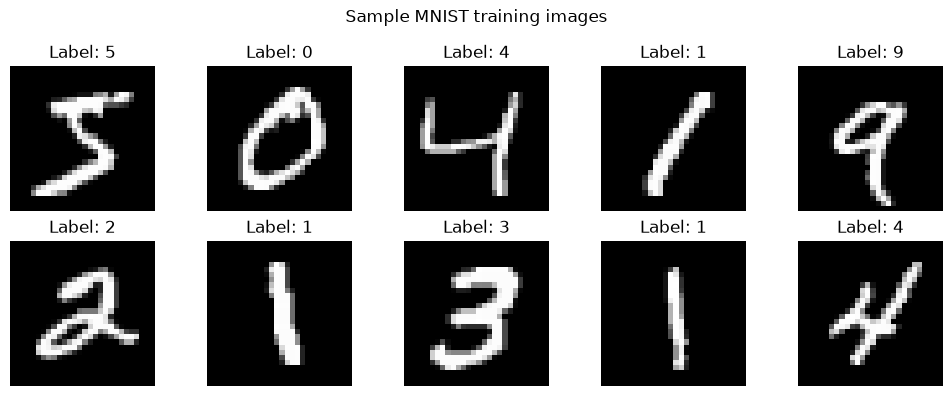

In [1]:
from pathlib import Path
import struct
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
ROOT = Path.cwd()
if not (ROOT / 'datasets').is_dir():
    ROOT = ROOT.parent
DATA = ROOT / 'datasets' / 'mnist'
FIGURES = ROOT / 'outputs' / 'figures'
RESULTS = ROOT / 'outputs' / 'results'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

def read_idx_images(path):
    with path.open('rb') as file:
        magic, count, rows, columns = struct.unpack('>IIII', file.read(16))
        if magic != 2051:
            raise ValueError(f'Unexpected IDX image magic number in {path}: {magic}')
        images = np.frombuffer(file.read(), dtype=np.uint8)
    if images.size != count * rows * columns:
        raise ValueError(f'IDX image count does not match the file size: {path}')
    return images.reshape(count, rows, columns)

def read_idx_labels(path):
    with path.open('rb') as file:
        magic, count = struct.unpack('>II', file.read(8))
        if magic != 2049:
            raise ValueError(f'Unexpected IDX label magic number in {path}: {magic}')
        labels = np.frombuffer(file.read(), dtype=np.uint8)
    if labels.size != count:
        raise ValueError(f'IDX label count does not match the file size: {path}')
    return labels

mnist_files = [DATA / name for name in ('train-images.idx3-ubyte', 'train-labels.idx1-ubyte', 't10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte')]
if all(path.is_file() for path in mnist_files):
    x_train = read_idx_images(mnist_files[0])
    y_train = read_idx_labels(mnist_files[1])
    x_test = read_idx_images(mnist_files[2])
    y_test = read_idx_labels(mnist_files[3])
    print('Dataset source: supplied MNIST IDX files in datasets/mnist/')
else:
    from tensorflow.keras.datasets import mnist
    (x_train, y_train), (x_test, y_test) = mnist.load_data()
    print('Dataset source: tensorflow.keras.datasets.mnist')

print('Training images:', x_train.shape, '| labels:', y_train.shape)
print('Test images:    ', x_test.shape, '| labels:', y_test.shape)
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.flat, x_train[:10], y_train[:10]):
    ax.imshow(image, cmap='gray')
    ax.set_title(f'Label: {label}')
    ax.axis('off')
fig.suptitle('Sample MNIST training images')
fig.tight_layout()
fig.savefig(FIGURES / 'exp08_mnist_samples.png', dpi=150, bbox_inches='tight')
plt.show()

## Normalise, build and train

Pixel intensities are converted to floating point values between 0 and 1. The model uses one ReLU hidden layer and is trained for five epochs.

In [2]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
print('Normalised pixel range:', float(x_train.min()), 'to', float(x_train.max()))

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax'),
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=2)

Normalised pixel range: 0.0 to 1.0


Epoch 1/5


422/422 - 4s - 8ms/step - accuracy: 0.8987 - loss: 0.3722 - val_accuracy: 0.9568 - val_loss: 0.1666


Epoch 2/5


422/422 - 2s - 4ms/step - accuracy: 0.9505 - loss: 0.1706 - val_accuracy: 0.9648 - val_loss: 0.1248


...

422/422 - 2s - 4ms/step - accuracy: 0.9647 - loss: 0.1227 - val_accuracy: 0.9670 - val_loss: 0.1108


Epoch 4/5


422/422 - 2s - 4ms/step - accuracy: 0.9726 - loss: 0.0962 - val_accuracy: 0.9685 - val_loss: 0.1036


Epoch 5/5


422/422 - 2s - 4ms/step - accuracy: 0.9777 - loss: 0.0783 - val_accuracy: 0.9698 - val_loss: 0.0990


## Training curves, test evaluation and predictions

The test set is held out from training and validation. The final grid displays the model prediction beside each actual digit.

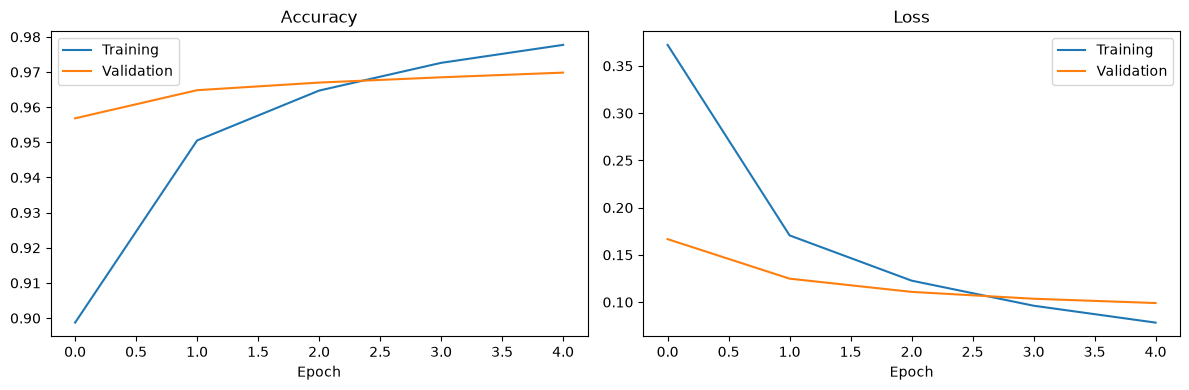

Test loss: 0.1014 | Test accuracy: 96.8000%


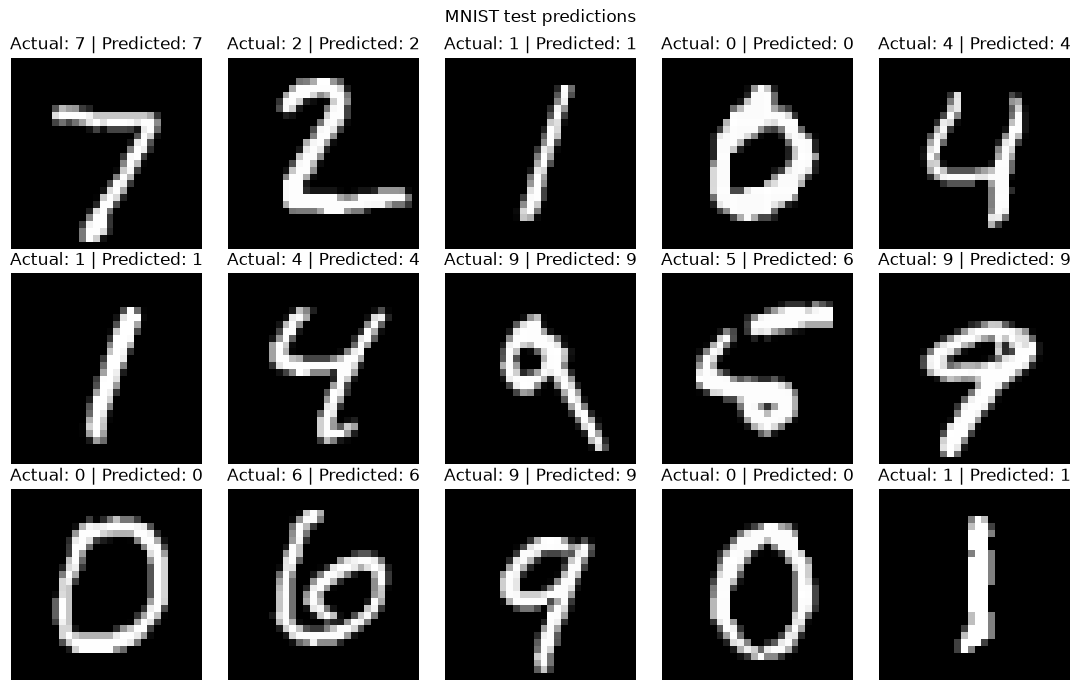

Conclusion: after 5 epochs, the neural network achieved 96.80% test accuracy.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, title in (('accuracy', 'Accuracy'), ('loss', 'Loss')):
    axes[0 if metric == 'accuracy' else 1].plot(history.history[metric], label='Training')
    axes[0 if metric == 'accuracy' else 1].plot(history.history[f'val_{metric}'], label='Validation')
    axes[0 if metric == 'accuracy' else 1].set_title(title)
    axes[0 if metric == 'accuracy' else 1].set_xlabel('Epoch')
    axes[0 if metric == 'accuracy' else 1].legend()
fig.tight_layout()
fig.savefig(FIGURES / 'exp08_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.4%}')
pd.DataFrame([{'epochs': len(history.history['loss']), 'test_loss': float(test_loss), 'test_accuracy': float(test_accuracy)}]).to_csv(RESULTS / 'exp08_mnist_metrics.csv', index=False)
probabilities = model.predict(x_test[:15], verbose=0)
predictions = probabilities.argmax(axis=1)
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for index, ax in enumerate(axes.flat):
    ax.imshow(x_test[index], cmap='gray')
    ax.set_title(f'Actual: {y_test[index]} | Predicted: {predictions[index]}')
    ax.axis('off')
fig.suptitle('MNIST test predictions')
fig.tight_layout()
fig.savefig(FIGURES / 'exp08_test_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Conclusion: after 5 epochs, the neural network achieved {test_accuracy:.2%} test accuracy.')

## Observation

Use the printed metrics, tables, plots, and predictions above as the measured observations for this run.

## Result

State the result using the actual output above and relate it to the experiment aim.